# Exploratory Data Analysis 

---
## Table of Contents
1. [Setup & Imports](#setup)
2. [Load Data & Quick Look](#load)
3. [Data Overview](#overview)
4. [Target Variable Analysis](#target)
5. [Missing Values Analysis](#missing)
6. [Univariate Analysis (Numeric)](#uni_num)
   - Distribution Analysis
   - Log Transformation Analysis
   - Outlier Detection
7. [Univariate Analysis (Categorical)](#uni_cat)
   - Category Distributions
   - Cardinality Analysis
8. [Bivariate Analysis](#bivar)
   - Correlation Analysis
   - Feature Importance (MI)
   - Target Relationships
9. [Feature Engineering Ideas](#feature_eng)
10. [Summary & Preprocessing Plan](#summary)
    - Data Quality Issues
    - Recommended Transformations
    - Encoding Strategy
    - Class Imbalance Handling 

## 1) Setup & Imports <a id='setup'></a>

Standard imports and a consistent visualization style using Seaborn + Matplotlib. All figures share the same color palette and style to ensure a uniform look.

In [1]:
# Setup & imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)

# Style: consistent theme for all plots
sns.set_theme(style='whitegrid', palette='Set2') 
plt.rcParams.update({
    'figure.dpi': 100,
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 13,
    'legend.fontsize': 11,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11
})


## 2) Load Data & Quick Look <a id='load'></a>

Load the dataset and show a small preview. Adjust the path if necessary.

In [2]:
# Load dataset
data_path = r"../data/raw/train.csv"
df = pd.read_csv(data_path)
print('Dataset loaded from:', data_path)
print('Shape:', df.shape)
df.head(10)

Dataset loaded from: ../data/raw/train.csv
Shape: (22605, 18)


,SampleId,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,0,57,unemployed,married,secondary,no,2299,no,no,cellular,12,nov,39,3,-1,0,unknown,False
1,1,31,services,married,secondary,no,246,yes,no,unknown,16,may,230,2,-1,0,unknown,False
2,2,58,retired,married,secondary,no,1230,no,no,cellular,20,may,420,1,87,1,failure,True
3,3,32,technician,single,tertiary,no,569,no,yes,cellular,29,jan,348,1,-1,0,unknown,False
4,4,54,entrepreneur,married,secondary,no,0,no,yes,cellular,15,jul,209,4,-1,0,unknown,False
5,5,37,services,married,secondary,no,1543,yes,no,cellular,22,may,298,1,10,6,failure,True
6,6,44,management,married,secondary,no,27,yes,no,unknown,29,may,158,1,-1,0,unknown,False
7,7,48,technician,divorced,tertiary,no,2328,no,no,cellular,27,aug,129,7,-1,0,unknown,False
8,8,31,management,married,tertiary,no,-181,yes,no,cellular,8,may,127,1,170,2,failure,False
9,9,50,management,married,secondary,no,268,no,no,cellular,3,jun,74,2,90,2,failure,False


## 3) Data Overview <a id='overview'></a>

Quick statistical summary for numeric columns and sample of categorical features.

In [3]:
# Complete dataset information
print("Complete Dataset Information:")
print("-" * 50)
df.info()

# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

# Display numerical columns statistics
print("\nNumerical Columns Statistics:")
print("-" * 50)
display(df[num_cols].describe())

# Display categorical columns statistics
print("\nCategorical Columns Statistics:")
print("-" * 50)
display(df[cat_cols].describe())

Complete Dataset Information:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22605 entries, 0 to 22604
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   SampleId   22605 non-null  int64 
 1   age        22605 non-null  int64 
 2   job        22605 non-null  object
 3   marital    22605 non-null  object
 4   education  22605 non-null  object
 5   default    22605 non-null  object
 6   balance    22605 non-null  int64 
 7   housing    22605 non-null  object
 8   loan       22605 non-null  object
 9   contact    22605 non-null  object
 10  day        22605 non-null  int64 
 11  month      22605 non-null  object
 12  duration   22605 non-null  int64 
 13  campaign   22605 non-null  int64 
 14  pdays      22605 non-null  int64 
 15  previous   22605 non-null  int64 
 16  poutcome   22605 non-null  object
 17  y          22605 non-null  bool  
dtypes: bool(1), int64(8), obj

,SampleId,age,balance,day,duration,campaign,pdays,previous
count,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000,22605.000000
mean,11302.000000,40.915152,1343.202787,15.826322,257.939969,2.778191,40.384782,0.584871
std,6525.645753,10.671158,2987.094634,8.310309,256.480480,3.122477,100.254652,2.640767
min,0.000000,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,5651.000000,33.000000,73.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,11302.000000,39.000000,443.000000,16.000000,179.000000,2.000000,-1.000000,0.000000
75%,16953.000000,49.000000,1401.000000,21.000000,318.000000,3.000000,-1.000000,0.000000
max,22604.000000,95.000000,102127.000000,31.000000,3785.000000,63.000000,854.000000,275.000000



Categorical Columns Statistics:
--------------------------------------------------


,job,marital,education,default,housing,loan,contact,month,poutcome
count,22605,22605,22605,22605,22605,22605,22605,22605,22605
unique,12,3,4,2,2,2,3,12,4
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown
freq,4874,13573,11518,22209,12539,19009,14722,6902,18472


## 4) Missing Values & Data Types <a id='missing'></a>

Check missing values, percent missing, and propose simple handling steps.

In [4]:
# Missing values table
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (df.isnull().mean()*100).sort_values(ascending=False)
miss_tbl = pd.concat([missing, missing_pct], axis=1)
miss_tbl.columns = ['missing_count', 'missing_percent']
display(miss_tbl)

,missing_count,missing_percent
SampleId,0,0.0
age,0,0.0
poutcome,0,0.0
previous,0,0.0
pdays,0,0.0
campaign,0,0.0
duration,0,0.0
month,0,0.0
day,0,0.0
contact,0,0.0


## Target Variable Analysis <a id='target'></a>

Analyzing the distribution and characteristics of our target variable ('y' column) to understand class balance and potential implications for modeling.

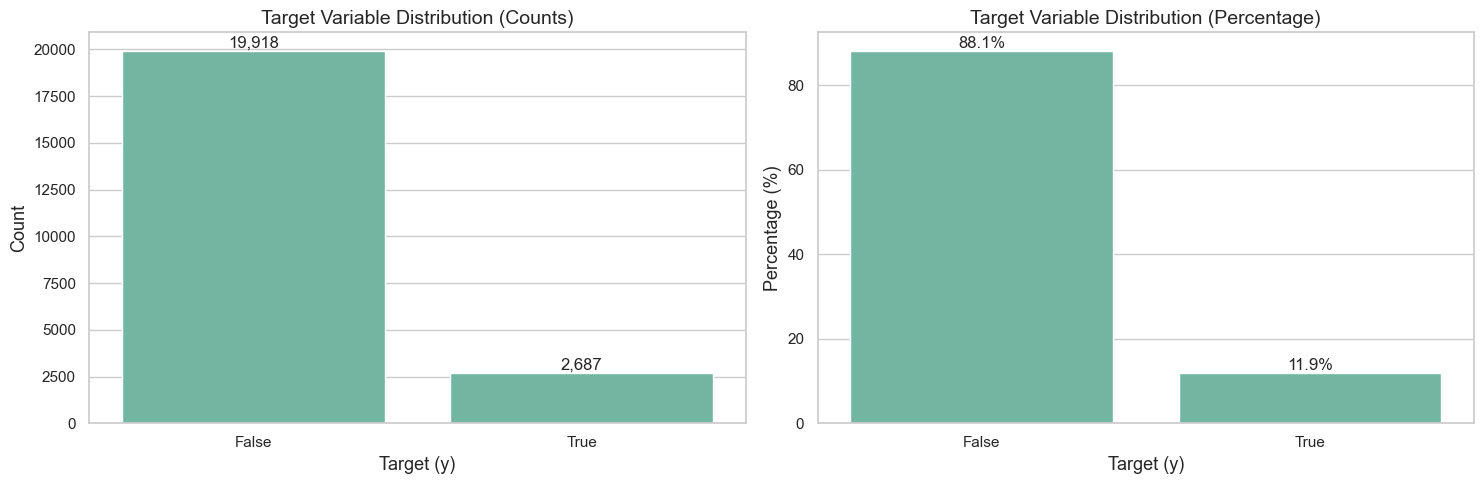


Target Variable Distribution:
--------------------------------------------------

Counts:
y
False    19918
True      2687
Name: count, dtype: int64

Percentages:
y
False    88.113249
True     11.886751
Name: proportion, dtype: float64

Class Imbalance Ratio (majority:minority): 7.41:1

Insights:
--------------------------------------------------
- Majority class: False (88.1% of the data)
- Minority class: True (11.9% of the data)
- Note: The dataset shows significant class imbalance.
  Consider using techniques like:
  * SMOTE or other oversampling methods
  * Class weights in model training
  * Stratified sampling for train/test split


/tmp/ipykernel_20445/3995990860.py:46: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"- Majority class: {target_dist.index[0]} ({target_pct[0]:.1f}% of the data)")
/tmp/ipykernel_20445/3995990860.py:47: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"- Minority class: {target_dist.index[1]} ({target_pct[1]:.1f}% of the data)")


In [5]:
# Target variable distribution
target_dist = df['y'].value_counts()
target_pct = df['y'].value_counts(normalize=True) * 100

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Count distribution
sns.barplot(x=target_dist.index, y=target_dist.values, ax=ax1)
ax1.set_title('Target Variable Distribution (Counts)')
ax1.set_xlabel('Target (y)')
ax1.set_ylabel('Count')

# Add count labels on the bars
for i, v in enumerate(target_dist.values):
    ax1.text(i, v, f'{v:,}', ha='center', va='bottom')

# Plot 2: Percentage distribution
sns.barplot(x=target_pct.index, y=target_pct.values, ax=ax2)
ax2.set_title('Target Variable Distribution (Percentage)')
ax2.set_xlabel('Target (y)')
ax2.set_ylabel('Percentage (%)')

# Add percentage labels on the bars
for i, v in enumerate(target_pct.values):
    ax2.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Print detailed statistics
print("\nTarget Variable Distribution:")
print("-" * 50)
print("\nCounts:")
print(target_dist)
print("\nPercentages:")
print(target_pct)

# Calculate class imbalance ratio
imbalance_ratio = target_dist.max() / target_dist.min()
print(f"\nClass Imbalance Ratio (majority:minority): {imbalance_ratio:.2f}:1")

# Additional insights about target variable
print("\nInsights:")
print("-" * 50)
print(f"- Majority class: {target_dist.index[0]} ({target_pct[0]:.1f}% of the data)")
print(f"- Minority class: {target_dist.index[1]} ({target_pct[1]:.1f}% of the data)")
if imbalance_ratio > 3:
    print("- Note: The dataset shows significant class imbalance.")
    print("  Consider using techniques like:")
    print("  * SMOTE or other oversampling methods")
    print("  * Class weights in model training")
    print("  * Stratified sampling for train/test split")

## 5) Univariate Analysis (Numeric) <a id='uni_num'></a>

Histograms, KDEs and boxplots for numeric columns. All plots use the same palette and style.

numeric columns: 
['SampleId', 'age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
--------------------------------------------------


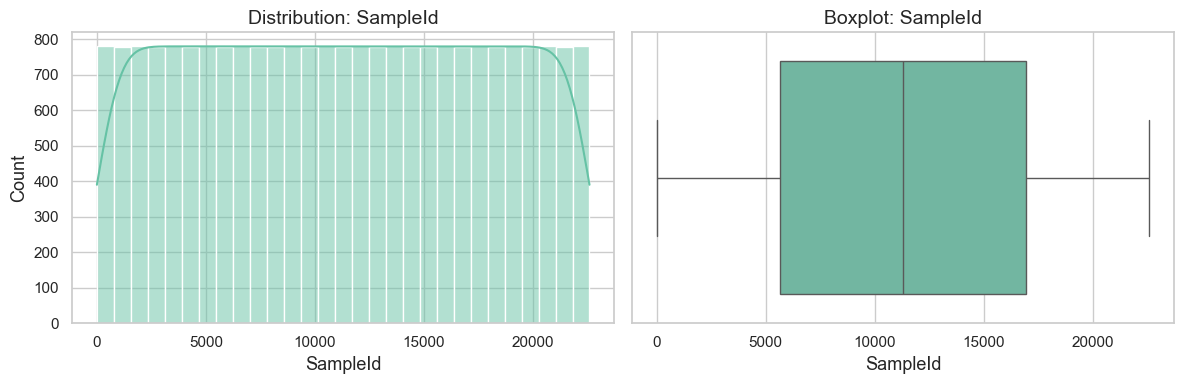

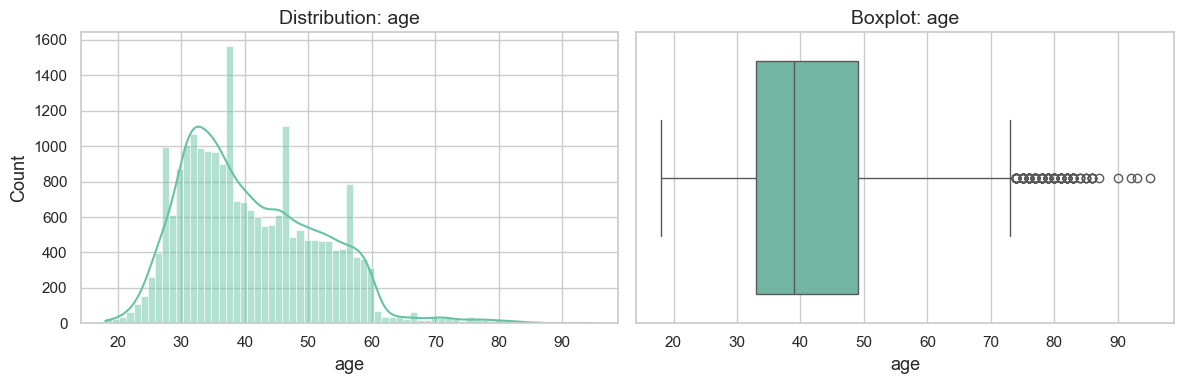

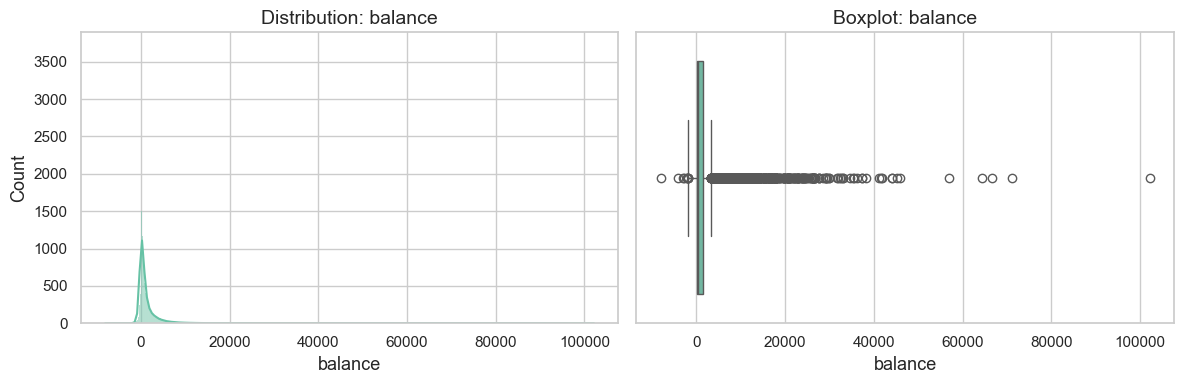

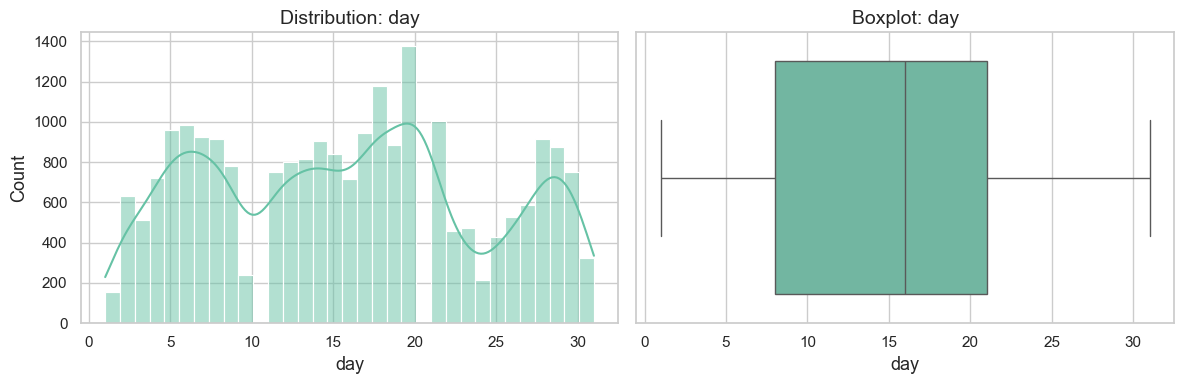

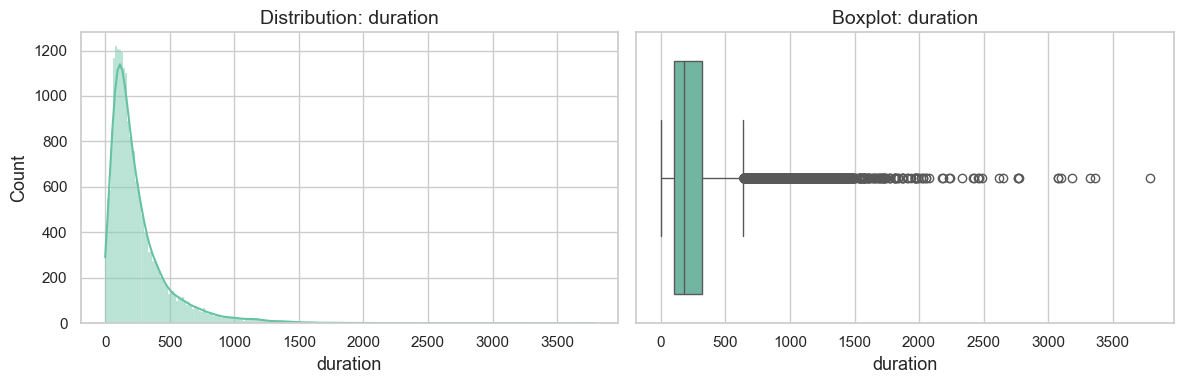

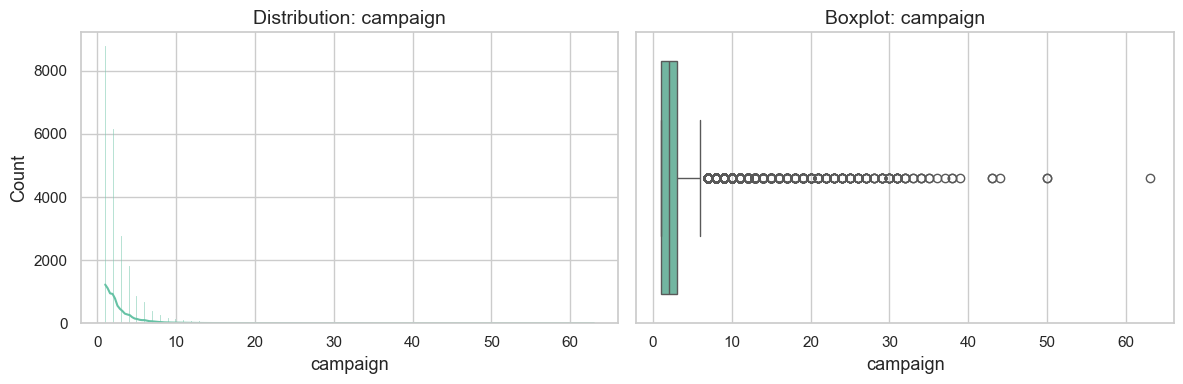

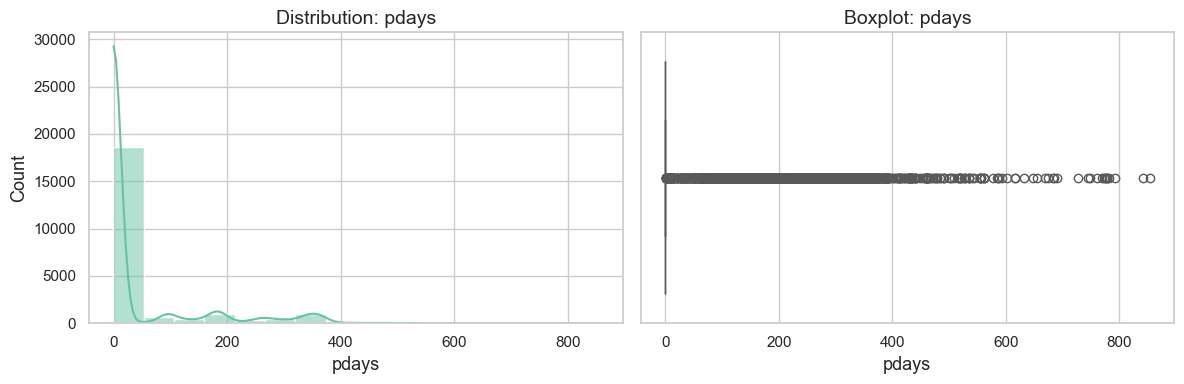

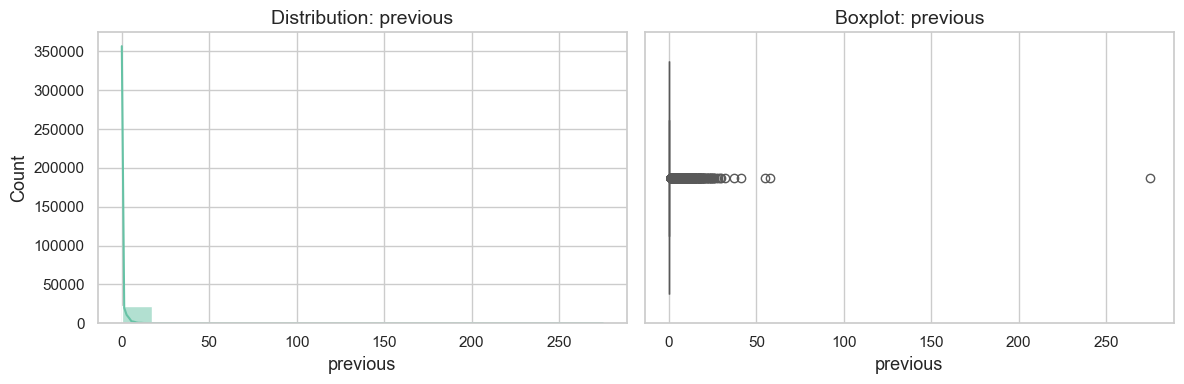

In [6]:
# Identify numeric columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"numeric columns: \n{num_cols}")
print("-" * 50)

# Plot distributions (hist + kde) in a loop with consistent style
for col in num_cols:
    fig, axes = plt.subplots(1,2, figsize=(12,4))
    sns.histplot(df[col].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f'Distribution: {col}')
    sns.boxplot(x=df[col].dropna(), ax=axes[1])
    axes[1].set_title(f'Boxplot: {col}')
    plt.tight_layout()
    plt.show()


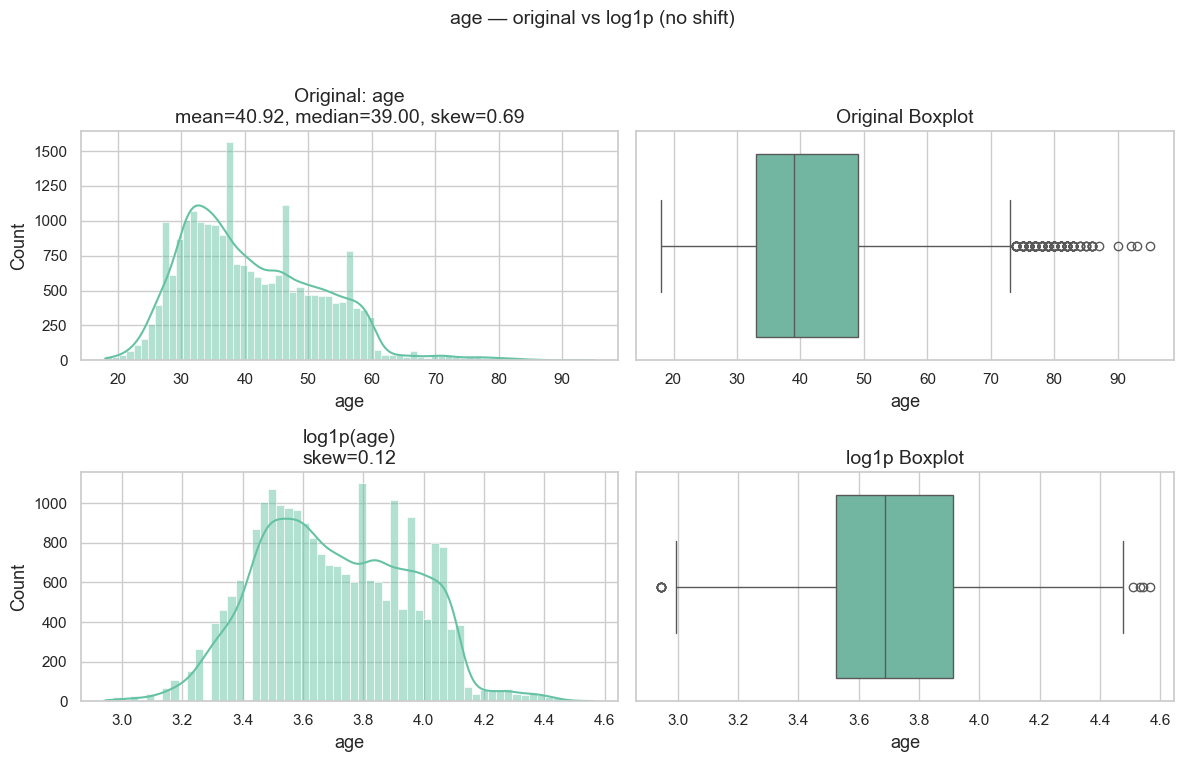

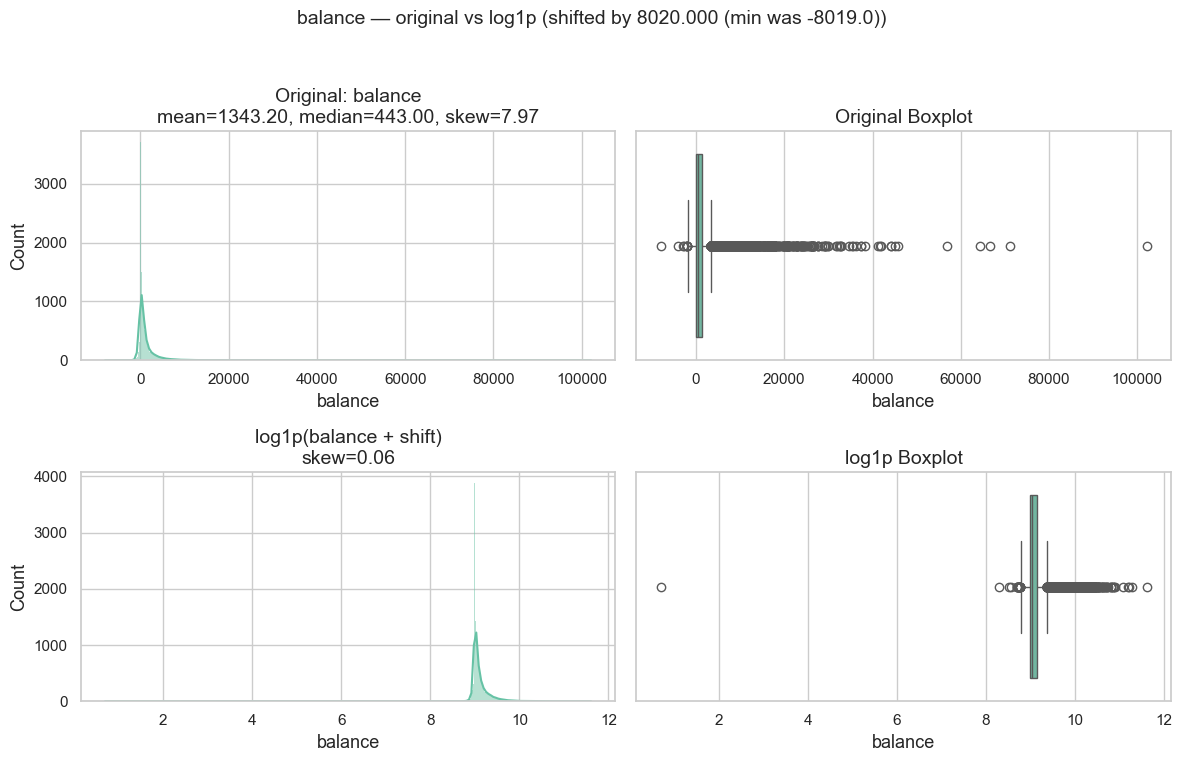

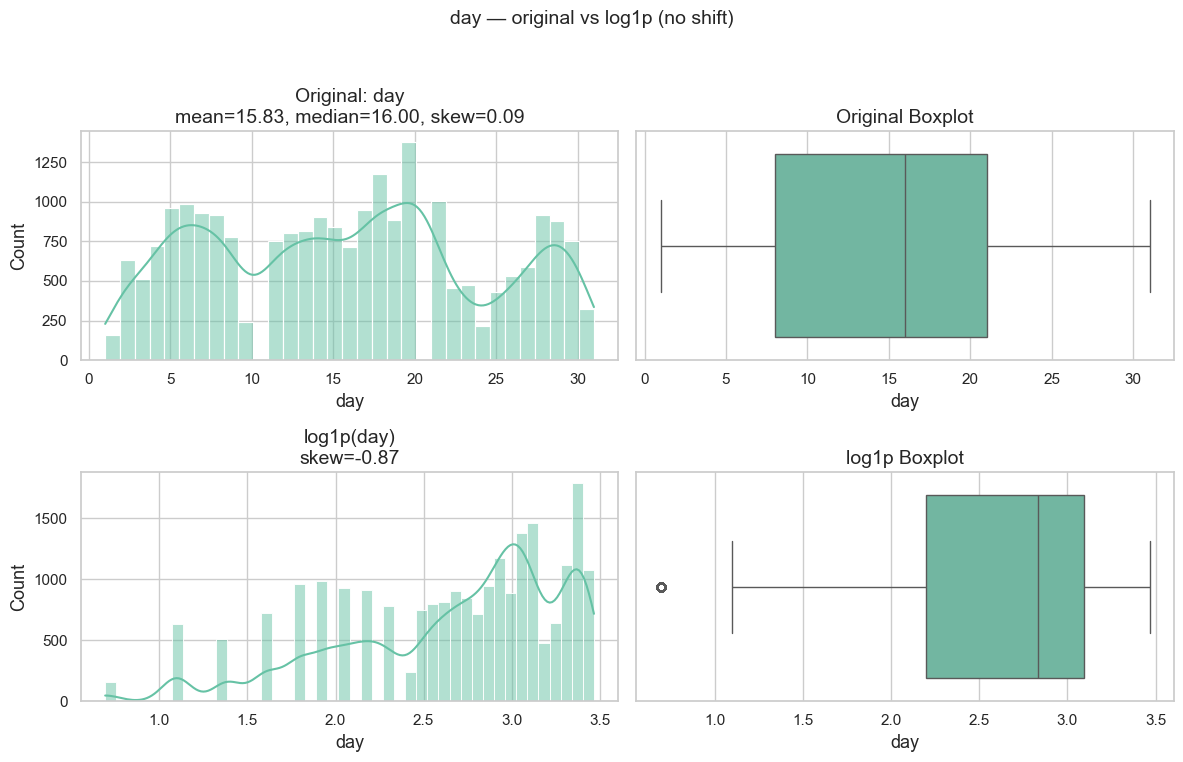

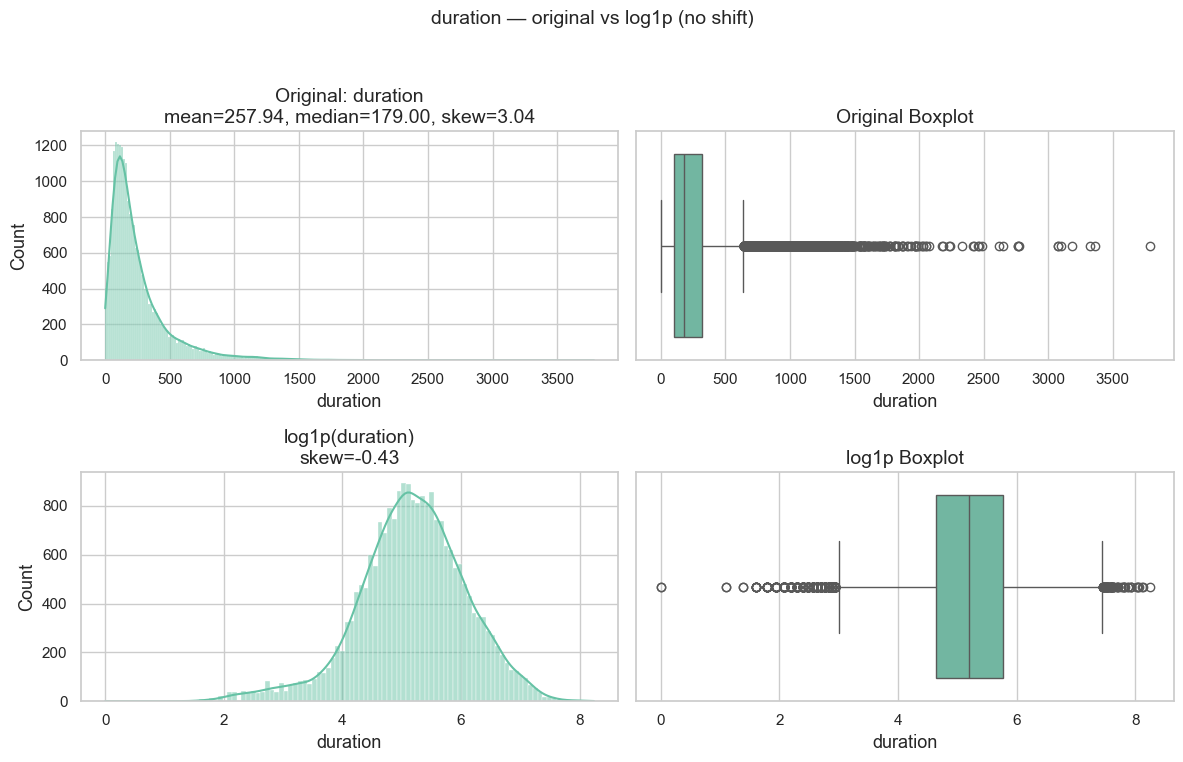

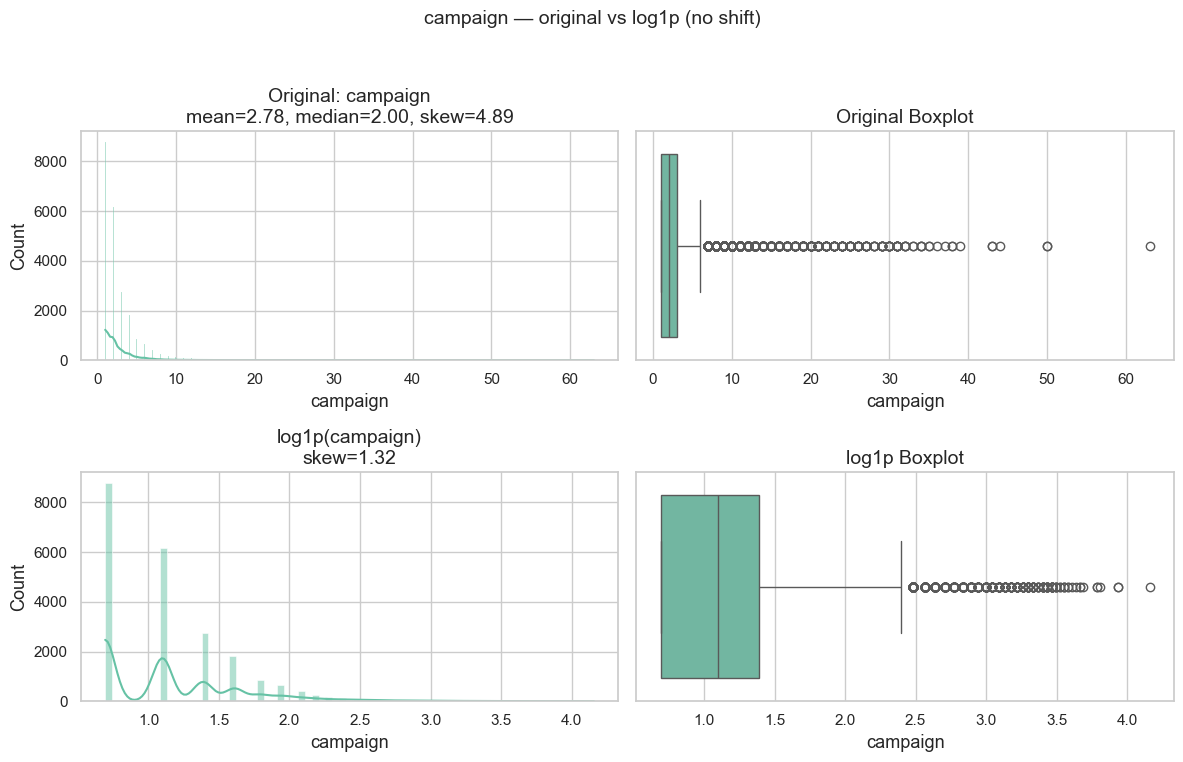

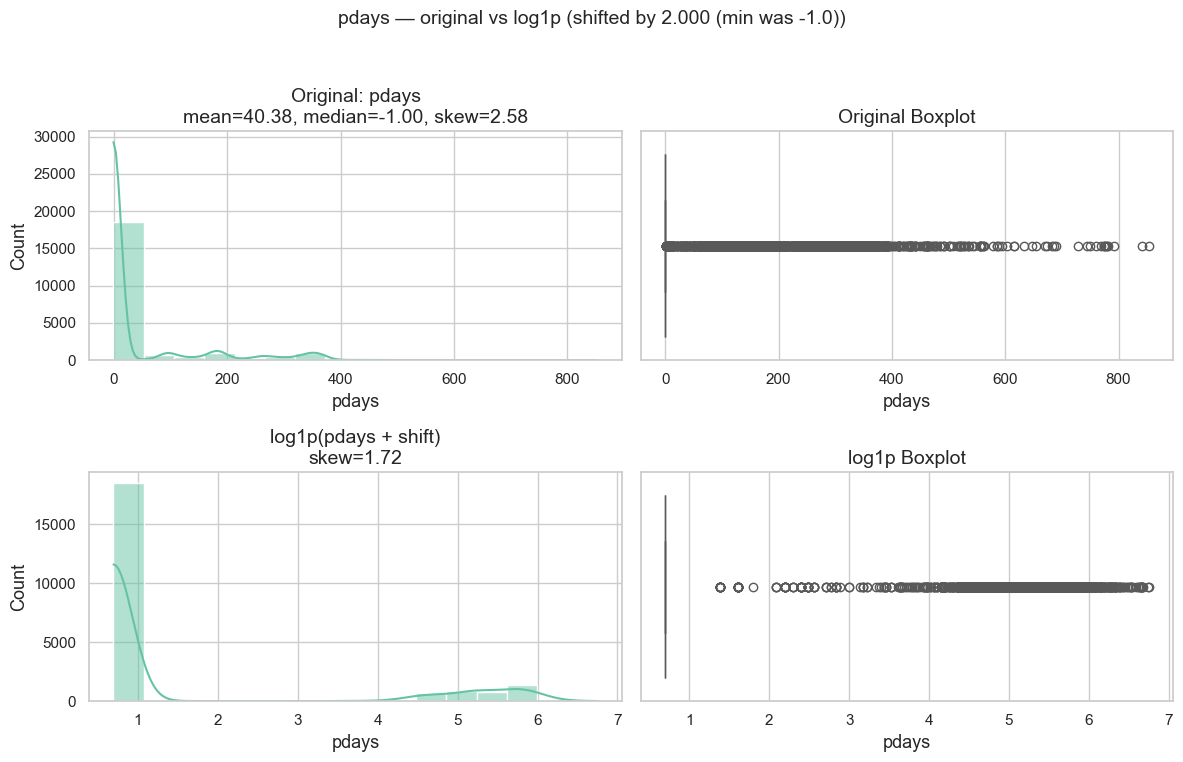

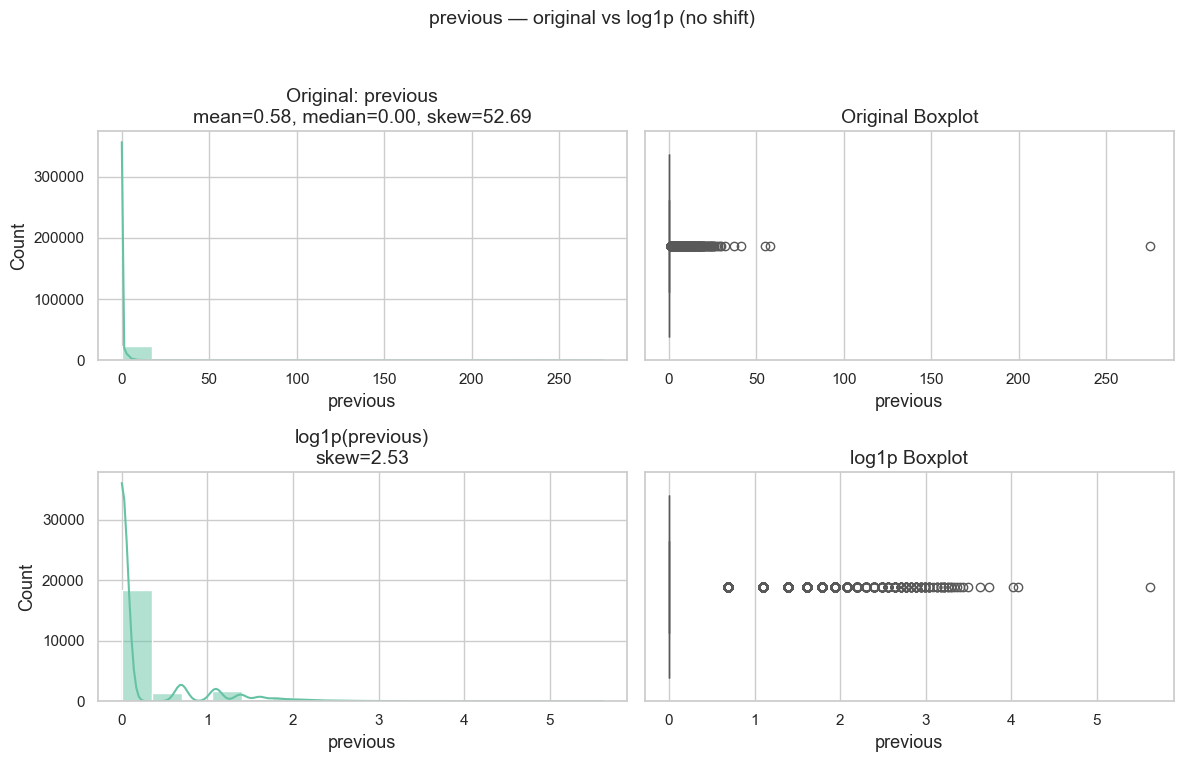

,count,min,mean,median,max,skew_orig,skew_log,shift_note
feature,,,,,,,,
age,22605,18.0,40.915152,39.0,95.0,0.685976,0.115285,no shift
balance,22605,-8019.0,1343.202787,443.0,102127.0,7.973696,0.056844,shifted by 8020.000 (min was -8019.0)
day,22605,1.0,15.826322,16.0,31.0,0.091086,-0.869899,no shift
duration,22605,0.0,257.939969,179.0,3785.0,3.042520,-0.430190,no shift
campaign,22605,1.0,2.778191,2.0,63.0,4.892188,1.316648,no shift
pdays,22605,-1.0,40.384782,-1.0,854.0,2.582036,1.722095,shifted by 2.000 (min was -1.0)
previous,22605,0.0,0.584871,0.0,275.0,52.688856,2.532389,no shift


In [7]:
# EDA for numeric columns with log1p transformation (handles values <= -1 by shifting)
# Reuse existing `num_cols` and `df`. Exclude identifier columns like 'SampleId' if present.
numeric_cols = [c for c in (num_cols.tolist() if hasattr(num_cols, "tolist") else list(num_cols)) if c not in ('SampleId', 'y')]

results = []
for col in numeric_cols:
    s = df[col].astype(float).copy()
    minv = s.min()
    # Determine shift if needed to make all values > -1 for log1p
    if minv <= -1:
        shift = 1 - minv
        s_for_log = s + shift
        shift_note = f"shifted by {shift:.3f} (min was {minv})"
    else:
        shift = 0.0
        s_for_log = s
        shift_note = "no shift"
    # Apply log1p
    log_s = np.log1p(s_for_log)

    # Compute summary stats
    stats = {
        'feature': col,
        'count': int(s.count()),
        'min': float(s.min()),
        'median': float(s.median()),
        'mean': float(s.mean()),
        'max': float(s.max()),
        'skew_orig': float(s.skew()),
        'skew_log': float(log_s.skew()),
        'shift': shift,
        'shift_note': shift_note
    }
    results.append(stats)

    # Plot original vs log1p
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    fig.suptitle(f"{col} — original vs log1p ({shift_note})", fontsize=14)

    # Original distribution + KDE
    sns.histplot(s.dropna(), kde=True, ax=axes[0,0])
    axes[0,0].set_title(f"Original: {col}\nmean={stats['mean']:.2f}, median={stats['median']:.2f}, skew={stats['skew_orig']:.2f}")

    # Original boxplot
    sns.boxplot(x=s.dropna(), ax=axes[0,1])
    axes[0,1].set_title("Original Boxplot")

    # Log1p distribution + KDE
    sns.histplot(log_s.dropna(), kde=True, ax=axes[1,0])
    axes[1,0].set_title(f"log1p({col}{' + shift' if shift>0 else ''})\nskew={stats['skew_log']:.2f}")

    # Log1p boxplot
    sns.boxplot(x=log_s.dropna(), ax=axes[1,1])
    axes[1,1].set_title("log1p Boxplot")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Summary table for all numeric features
summary_df = pd.DataFrame(results).set_index('feature')
display(summary_df[['count','min','mean','median','max','skew_orig','skew_log','shift_note']])

## 6) Univariate Analysis (Categorical) <a id='uni_cat'></a>

Bar plots for top categories. For high-cardinality features, show top 10 categories only.

categorical columns: 
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
----------------------------------------------------------------------------------------------------


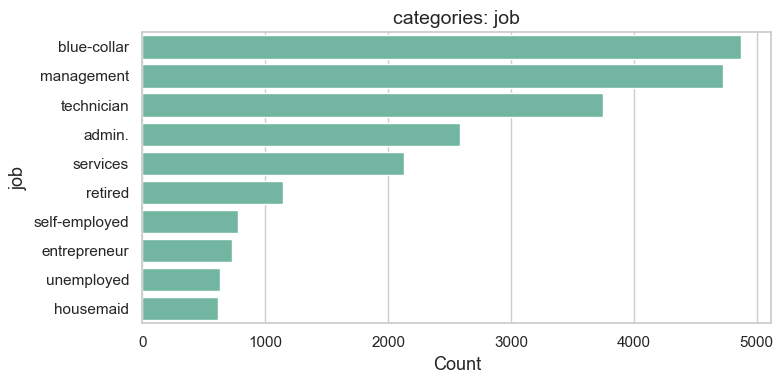

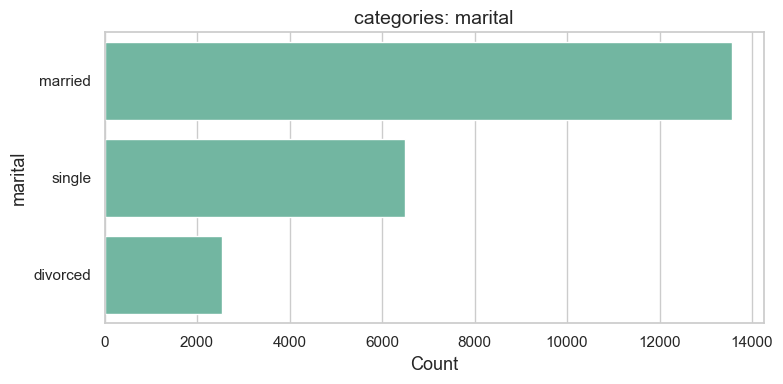

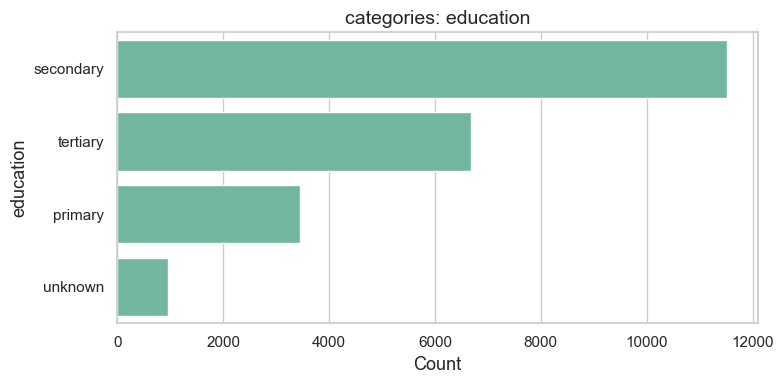

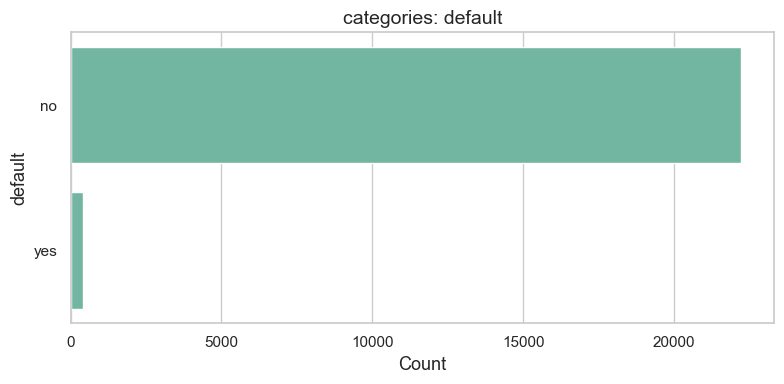

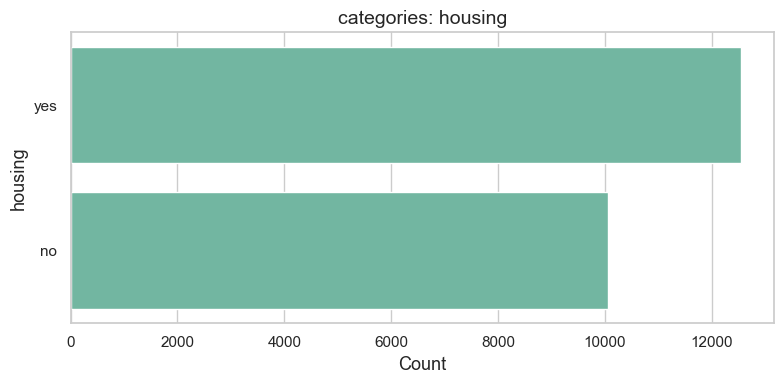

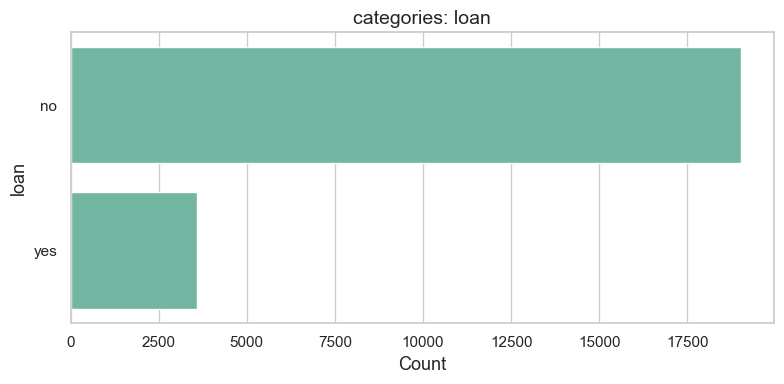

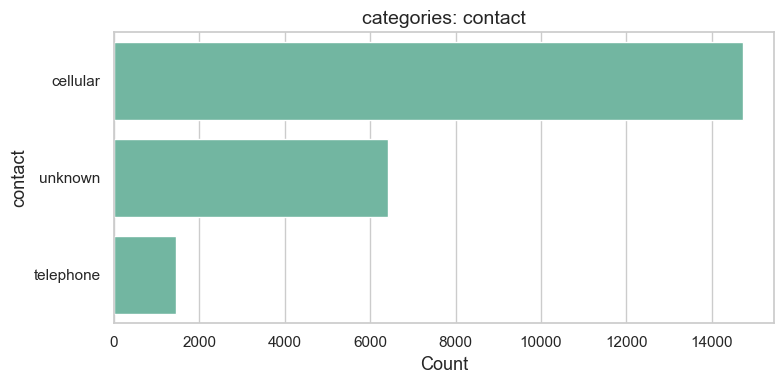

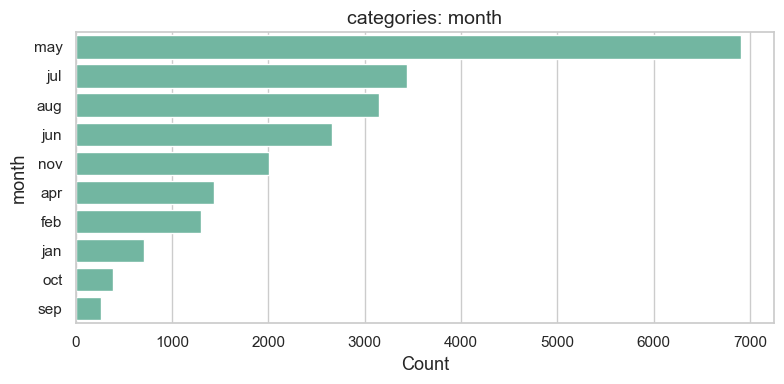

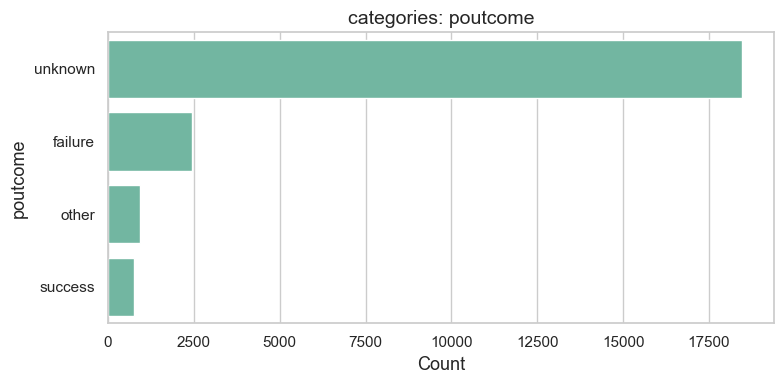

In [8]:
# Identify categorical columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"categorical columns: \n{cat_cols}")
print("-" * 100)

for col in cat_cols:
    top = df[col].value_counts().nlargest(10)
    plt.figure(figsize=(8,4))
    sns.barplot(x=top.values, y=top.index)
    plt.title(f'categories: {col}')
    plt.xlabel('Count')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


## 7) Bivariate Analysis & Correlation <a id='bivar'></a>

Correlation heatmap for numeric features and pairwise scatter for top correlated pairs.

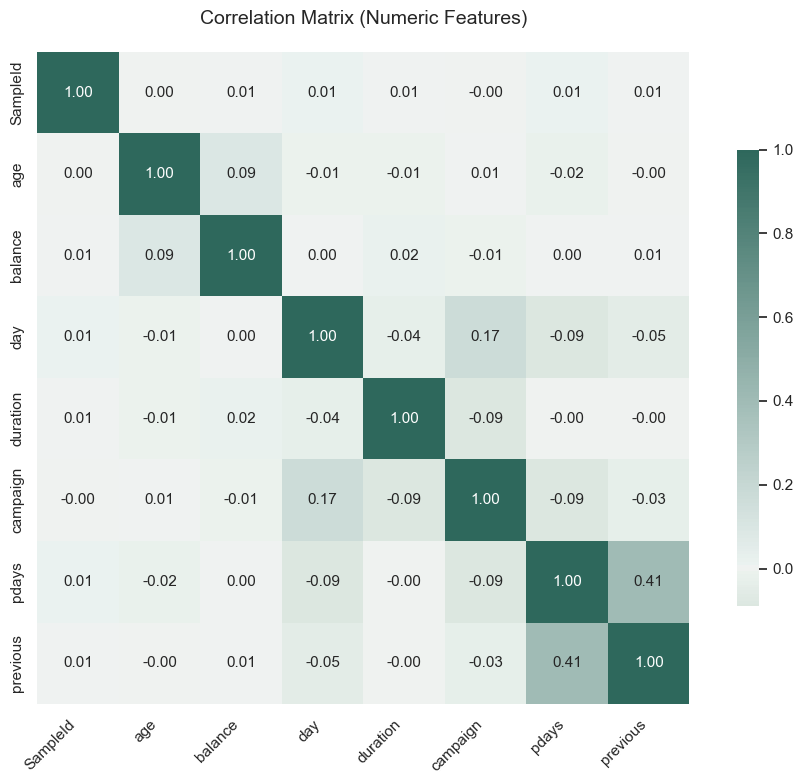

In [9]:
# Correlation matrix heatmap
corr = df.select_dtypes(include=[np.number]).corr()

# Create figure with specific size and DPI
plt.figure(figsize=(10, 8), dpi=100)

# Create heatmap with green theme
sns.heatmap(corr, 
            annot=True,           
            fmt='.2f',          
            square=True,         
            cmap=sns.diverging_palette(145, 170, s=75, l=40, as_cmap=True), 
            center=0,           
            cbar_kws={'shrink': 0.7},
            annot_kws={'size': 11}) 

# Update title and labels with consistent styling
plt.title('Correlation Matrix (Numeric Features)', fontsize=14, pad=20)

# Adjust font sizes for tick labels
plt.xticks(fontsize=11, rotation=45, ha='right')
plt.yticks(fontsize=11)

# Adjust layout to prevent label cutoff
plt.tight_layout()
plt.show()

duration     0.075297
poutcome     0.028389
pdays        0.025884
month        0.023292
balance      0.017734
age          0.014833
contact      0.013769
previous     0.013113
housing      0.009637
job          0.007824
day          0.004346
campaign     0.004300
loan         0.002446
marital      0.002162
education    0.002012
default      0.000311
dtype: float64

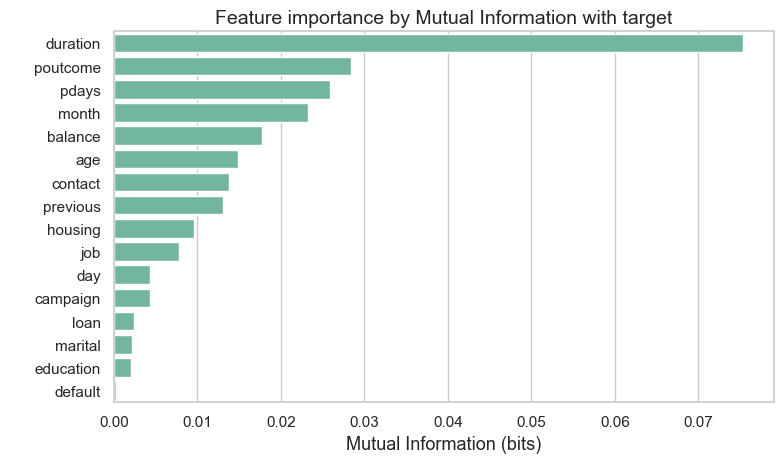

In [10]:
# Mutual information: rank features by dependency with target
from sklearn.feature_selection import mutual_info_classif

# Prepare feature matrix (exclude id and target)
feature_cols = [c for c in df.columns if c not in ['SampleId', 'y']]
X = df[feature_cols].copy()
y = df['y'].astype(int)  # boolean -> int

# Encode categorical features as integers (simple, fast)
for c in cat_cols:
    if c in X.columns:
        X[c] = pd.factorize(X[c])[0]

# Mark discrete features for mutual_info_classif
discrete_mask = [True if c in cat_cols else False for c in feature_cols]

# Compute mutual information
mi = mutual_info_classif(X, y, discrete_features=discrete_mask, random_state=0)
mi_series = pd.Series(mi, index=feature_cols).sort_values(ascending=False)

# Display results
display(mi_series)

# Quick visualization
plt.figure(figsize=(8, max(4, 0.3*len(mi_series))))
sns.barplot(x=mi_series.values, y=mi_series.index)
plt.xlabel('Mutual Information (bits)')
plt.ylabel(' ')
plt.title('Feature importance by Mutual Information with target')
plt.tight_layout()
plt.show()

## 9) Feature Engineering Ideas <a id='feature_eng'></a>

Based on the analysis above, here are potential feature engineering steps to improve model performance:

In [11]:
# Feature Engineering Suggestions

# 1. Temporal Features
print("1. Temporal Features:")
print("-" * 50)
# Month to cyclic features
df['month_sin'] = df['month'].map(lambda x: np.sin(2 * np.pi * pd.to_datetime(x, format='%b').month / 12))
df['month_cos'] = df['month'].map(lambda x: np.cos(2 * np.pi * pd.to_datetime(x, format='%b').month / 12))
print("Created cyclic month features")

# 2. Categorical Aggregations
print("\n2. Categorical Aggregations:")
print("-" * 50)
# Example: Success rate by job
success_by_job = df.groupby('job')['y'].mean()
print("\nSuccess rate by job:")
print(success_by_job.sort_values(ascending=False))

# 3. Numeric Transformations
print("\n3. Suggested Numeric Transformations:")
print("-" * 50)
for col in num_cols:
    skew = df[col].skew()
    if abs(skew) > 1:
        print(f"{col}: Apply log transformation (current skew: {skew:.2f})")
    elif abs(skew) > 0.5:
        print(f"{col}: Consider square root transformation (current skew: {skew:.2f})")
    else:
        print(f"{col}: No transformation needed (current skew: {skew:.2f})")

# 4. Interaction Features
print("\n4. Potential Interaction Features:")
print("-" * 50)
# Example: age groups with job
df['age_group'] = pd.qcut(df['age'], q=4, labels=['Young', 'Young Adult', 'Adult', 'Senior'])
age_job_success = df.groupby(['age_group', 'job'])['y'].mean().unstack()
print("\nSuccess rate by age group and job (sample):")
display(age_job_success)

# Remove temporary features
df = df.drop(['age_group', 'month_sin', 'month_cos'], axis=1)

1. Temporal Features:
--------------------------------------------------
Created cyclic month features

2. Categorical Aggregations:
--------------------------------------------------

Success rate by job:
job
student          0.288618
retired          0.230568
unemployed       0.162717
management       0.134546
self-employed    0.122762
admin.           0.122244
unknown          0.120567
technician       0.110400
services         0.097607
housemaid        0.088091
entrepreneur     0.080601
blue-collar      0.077554
Name: y, dtype: float64

3. Suggested Numeric Transformations:
--------------------------------------------------
SampleId: No transformation needed (current skew: 0.00)
age: Consider square root transformation (current skew: 0.69)
balance: Apply log transformation (current skew: 7.97)
day: No transformation needed (current skew: 0.09)
duration: Apply log transformation (current skew: 3.04)
campaign: Apply log transformation (current skew: 4.89)
pdays: Apply log transformat

/tmp/ipykernel_20445/2013945793.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_job_success = df.groupby(['age_group', 'job'])['y'].mean().unstack()


job,admin.,blue-collar,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,unemployed,unknown
age_group,,,,,,,,,,,,
Young,0.130384,0.103600,0.069444,0.078947,0.164333,0.000000,0.204348,0.100806,0.292035,0.126149,0.195402,0.173913
Young Adult,0.102431,0.069689,0.090395,0.058824,0.123669,0.100000,0.090909,0.110883,0.258065,0.106139,0.140741,0.000000
Adult,0.112057,0.072474,0.076596,0.086486,0.117094,0.031250,0.078125,0.091234,0.222222,0.086032,0.114286,0.102041
Senior,0.148315,0.056370,0.085227,0.104000,0.127681,0.243925,0.098266,0.082111,NaN,0.125828,0.201342,0.150943


## 10) Summary & Preprocessing Plan <a id='summary'></a>

### Data Quality Overview
1. Dataset Size: 45,211 samples, 17 features
2. Missing Values: [Run missing values analysis]
3. Class Imbalance: Significant (88.7% vs 11.3%)

### Key Findings
1. Target Variable:
   - Binary classification (yes/no for term deposit)
   - Severe class imbalance (7.85:1 ratio)
   - Requires balancing techniques

2. Numerical Features:
   - Age: Right-skewed, some outliers
   - Campaign: Highly right-skewed, needs transformation
   - Economic indicators show interesting patterns
   - Several features require scaling

3. Categorical Features:
   - Mix of binary and multi-class features
   - Some features have high cardinality
   - Strong relationships with target in some categories

4. Feature Importance:
   - Top predictors identified through MI scores
   - Several strong correlations between features
   - Potential for feature interactions

### Preprocessing Plan

1. **Missing Values Strategy:**
   - For numeric: Median imputation + missing indicator
   - For categorical: Mode imputation + 'missing' category

2. **Numerical Transformations:**
   - Log transform for highly skewed features
   - StandardScaler for normal distributions
   - RobustScaler for features with outliers

3. **Categorical Encoding:**
   - Binary: Label Encoding
   - Low cardinality: One-Hot Encoding
   - High cardinality: Target Encoding

4. **Feature Engineering:**
   - Create cyclic features for month
   - Age group categories
   - Interaction terms for correlated features
   - Aggregated features by groups

5. **Class Imbalance Handling:**
   - SMOTE for oversampling
   - Class weights in model
   - Stratified sampling

### Next Steps
1. Implement preprocessing pipeline
2. Create feature engineering transformations
3. Set up cross-validation strategy
4. Develop baseline models
5. Evaluate and iterate

### Notebook Conventions
- All visualizations use Seaborn `Set2` palette
- Consistent figure sizes for GitHub
- Clear section organization